# Group B – K-Nearest Neighbours (KNN)
## Can we identify a wheat variety by comparing it with similar kernels?

**The question:** if I measure a new wheat kernel, can I work out its variety by looking at the most similar kernels I already know?

**The data:** the *Seeds* dataset, which has 210 real wheat kernels measured from X-ray images. There are 70 kernels from each of three varieties: **Kama**, **Rosa** and **Canadian**. A kernel is a single grain of wheat.

The dataset has seven measurements for each kernel. I use just two of them:

* **Kernel length:** how long the grain is, in mm
* **Groove length:** how long the crease along the grain is, in mm

With only two measurements, every kernel fits on a simple chart, so we can actually see how KNN works.

**What I will do:**
1. Look at the data
2. Learn how KNN works
3. Keep some kernels aside for testing
4. Watch KNN identify one new kernel
5. Choose the best number of neighbours
6. Test the final model
7. Identify some new kernels

*Data source: Charytanowicz et al. (2010), "Seeds", UCI Machine Learning Repository, https://doi.org/10.24432/C5H30K (CC BY 4.0).*

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Make every chart clean and easy to read
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 12, "axes.grid": True, "grid.color": "#e6e5e0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
COLOURS = {"Kama": "#2a78d6", "Rosa": "#eb6834", "Canadian": "#1baf7a"}
MARKERS = {"Kama": "o", "Rosa": "s", "Canadian": "^"}


def draw_kernels(X, y):
    "Draw each kernel as a dot, with a different colour and shape for each variety."
    for variety in COLOURS:
        group = X[y == variety]
        plt.scatter(group["kernel_length_mm"], group["groove_length_mm"], color=COLOURS[variety],
                    marker=MARKERS[variety], alpha=0.6, edgecolor="white", label=variety)
    plt.xlabel("Kernel length (mm)")
    plt.ylabel("Groove length (mm)")

### Step 1: Look at the data
I load the kernels and look at a few of them.

In [2]:
wheat = pd.read_csv("data/seeds.csv")
X = wheat[["kernel_length_mm", "groove_length_mm"]]    # the measurements
y = wheat["variety"].values                            # the variety

print(pd.Series(y).value_counts())
X.assign(variety=y).sample(5, random_state=1)

Kama        70
Rosa        70
Canadian    70
Name: count, dtype: int64


,kernel_length_mm,groove_length_mm,variety
44,5.579,5.180,Kama
188,5.089,4.957,Canadian
51,5.674,5.136,Kama
204,5.204,5.001,Canadian
35,5.709,5.443,Kama


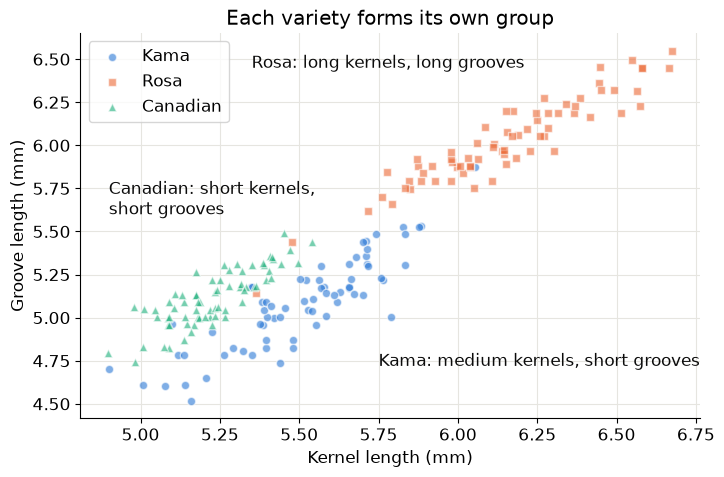

In [3]:
draw_kernels(X, y)
plt.text(5.35, 6.45, "Rosa: long kernels, long grooves", color="#0b0b0b")
plt.text(5.75, 4.72, "Kama: medium kernels, short grooves", color="#0b0b0b")
plt.text(4.9, 5.6, "Canadian: short kernels,\nshort grooves", color="#0b0b0b")
plt.title("Each variety forms its own group")
plt.legend(loc="upper left")
plt.show()

**What the chart shows:** each mark is one kernel, and kernels of the same variety sit close together. Most Rosa kernels are high up and to the right, away from the others, so they are easy to spot, although a few unusual ones sit lower down. Kama and Canadian have similar grooves and touch each other, so those two are harder to separate.

This is why KNN suits this data: kernels that are close together on the chart are usually the same variety.

### Step 2: How does KNN work?
KNN makes a guess by looking at the most similar examples it already knows. It is like asking your closest neighbours for their opinion.

To identify a new kernel, it does three things:
1. **Measure the distance** to every kernel it knows. On our chart, this is simply how far apart two kernels are. A small distance means they are very similar.
2. **Pick the K closest kernels.** These are the "nearest neighbours", and K is a number that I choose.
3. **Let the neighbours vote.** The most common variety wins. If K is 5 and 4 neighbours are Kama, the guess is Kama.

KNN doesn't really learn anything in advance. It just remembers all the examples and compares each new kernel with them.

**A note on scale:** KNN works on distance, so measurements need to be on a similar scale. Both of ours are in millimetres and are similar sizes, so that is fine here. If one was in grams and the other in metres, the bigger numbers would decide everything, and we would rescale them first.

### Step 3: Keep some kernels aside for testing
A student who has seen the exam answers will score well, but that doesn't prove they understand the subject.
So I split the kernels into two groups:

* **Practice kernels (75%):** the examples KNN remembers
* **Test kernels (25%):** kept hidden, to check how well it handles new kernels

In [4]:
X_practice, X_test, y_practice, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print("Practice kernels:", len(X_practice))
print("Test kernels:", len(X_test))

Practice kernels: 157
Test kernels: 53


`stratify=y` keeps the same mix of varieties in both groups.

### Step 4: Watch KNN identify one new kernel
Here is a new kernel with a length of 5.5 mm and a groove length of 5.2 mm. I use 5 neighbours for now. The star on the chart is the new kernel, and the black circles mark its 5 closest neighbours.

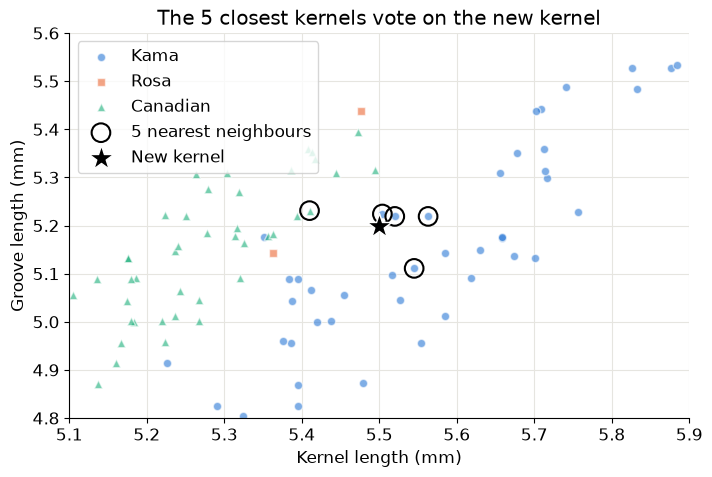

KNN's guess: Kama


,kernel_length_mm,groove_length_mm,variety,distance
53,5.504,5.224,Kama,0.02
21,5.520,5.219,Kama,0.03
6,5.563,5.219,Kama,0.07
198,5.410,5.231,Canadian,0.10
48,5.545,5.111,Kama,0.10


In [5]:
model = KNeighborsClassifier(n_neighbors=5).fit(X_practice, y_practice)

new_kernel = pd.DataFrame([[5.5, 5.2]], columns=X.columns)
distances, positions = model.kneighbors(new_kernel)
neighbours = X_practice.iloc[positions[0]]

draw_kernels(X_practice, y_practice)
plt.scatter(neighbours["kernel_length_mm"], neighbours["groove_length_mm"], s=180, facecolor="none",
            edgecolor="black", linewidth=1.5, label="5 nearest neighbours")
plt.scatter(5.5, 5.2, marker="*", s=350, color="black", edgecolor="white", label="New kernel")
plt.xlim(5.1, 5.9)
plt.ylim(4.8, 5.6)
plt.title("The 5 closest kernels vote on the new kernel")
plt.legend(loc="upper left")
plt.show()

votes = neighbours.assign(variety=y_practice[positions[0]], distance=distances[0].round(2))
print("KNN's guess:", model.predict(new_kernel)[0])
votes

**What this shows:** the vote is 4 Kama to 1 Canadian, so KNN guesses **Kama**. The one Canadian vote is there because this kernel sits near where the two varieties meet.

The chart is zoomed in around the new kernel. Most Rosa kernels are off the chart, and the two shown here are unusually small ones.

This is the whole method: find the closest kernels and let them vote.

### Step 5: Choose the best number of neighbours (K)
I can't use the test kernels to choose K, because that would be like peeking at the exam. Instead I use **cross-validation**:

1. Split the practice kernels into 5 parts
2. Let each part take a turn as a mini test, while the other 4 are used as examples
3. Average the 5 scores

I try odd values of K, because an odd number of voters is less likely to tie.

Best K = 7, with a score of 94.9%


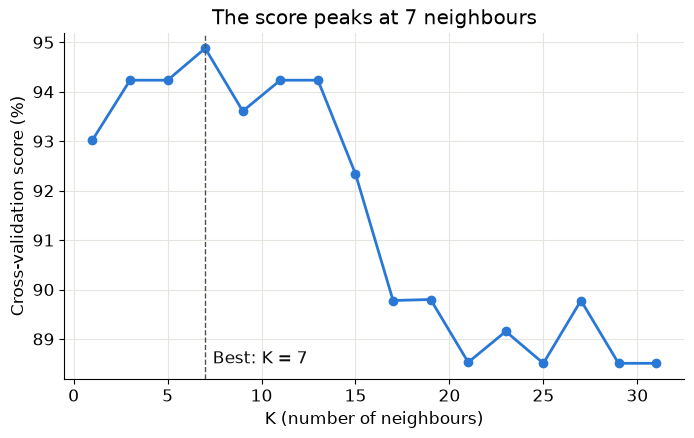

In [6]:
k_values = list(range(1, 32, 2))
scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores.append(cross_val_score(knn, X_practice, y_practice, cv=5).mean() * 100)

best_k = k_values[scores.index(max(scores))]
print(f"Best K = {best_k}, with a score of {max(scores):.1f}%")

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, scores, "o-", color="#2a78d6", lw=2)
plt.axvline(best_k, color="#52514e", ls="--", lw=1)
plt.text(best_k + 0.4, min(scores), f"Best: K = {best_k}", color="#0b0b0b")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Cross-validation score (%)")
plt.title("The score peaks at 7 neighbours")
plt.show()

**What this shows:**
* **K = 7 has the best score,** at 94.9%. It only just wins: K = 3, 5, 11 and 13 all score 94.2%, and one practice kernel is worth less than 1%.
* **K = 1 scores a little lower,** at 93.0%. With only one neighbour, one unusual kernel can change the guess. This is **overfitting**.
* **K = 17 and above score lowest,** at about 88% to 90%, because the vote starts to include kernels that aren't really similar. This is **underfitting**.

### Step 6: Test the final model
Now I check the final model on the test kernels, which it has never seen. The table shows the real variety in each row and the model's guess in each column.

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_practice, y_practice)
guesses = knn.predict(X_test)

print(f"Correct on test kernels: {knn.score(X_test, y_test):.1%}")
pd.crosstab(y_test, guesses, rownames=["Real variety"], colnames=["Model's guess"])

Correct on test kernels: 94.3%


Model's guess,Canadian,Kama,Rosa
Real variety,,,
Canadian,17,0,0
Kama,3,15,0
Rosa,0,0,18


**What this shows:** the model gets 50 of the 53 test kernels right, which is 94.3%.
* All 18 Rosa kernels and all 17 Canadian kernels were identified correctly.
* There were 3 mistakes, and all of them were Kama kernels guessed as Canadian. These are the two varieties that touch on the chart.

This score is very close to the 94.9% in Step 5, which suggests the cross-validation score was a fair estimate. There are only 53 test kernels, so each mistake costs about 1.9%. The test score is the one to trust, because the model had never seen these kernels.

### Step 7: Identify some new kernels
I give the model three made-up kernels and ask it to identify them.

In [8]:
new_kernels = pd.DataFrame([
    [5.2, 4.9],
    [5.7, 5.1],
    [6.3, 6.1],
], columns=X.columns)

new_kernels.assign(guess=knn.predict(new_kernels))

,kernel_length_mm,groove_length_mm,guess
0,5.2,4.9,Canadian
1,5.7,5.1,Kama
2,6.3,6.1,Rosa


### Conclusion
* KNN gets about **94%** of new kernels right, just by comparing each one with the most similar kernels it knows.
* The whole method is simple: **measure the distance, pick the K closest, and let them vote.**
* **K = 7** was chosen with cross-validation. Very small K can be misled by one unusual kernel, and very large K brings in kernels that aren't really similar.
* The mistakes happen where Kama and Canadian overlap, because kernels there have neighbours from both varieties.
* KNN can be slow on very large datasets, because it compares each new case with every example it remembers.
* **Main lesson:** things that are similar usually belong together, and that simple idea can be enough to make good guesses.